In [1]:
# Importación de librerías y configuración inicial
import json
import matplotlib.pyplot as plt
import tensorflow as tf

# Configuración de hiperparámetros
DATASET_DIR = "dataset"
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

print(f"Versión de TensorFlow: {tf.__version__}")

Versión de TensorFlow: 2.21.0


In [2]:
# Carga del dataset, partición (80/20) y exportación de clases
# Carga del conjunto de entrenamiento (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    crop_to_aspect_ratio=True # Evita la distorsión de imágenes rectangulares
)

# Carga del conjunto de validación (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    crop_to_aspect_ratio=True # Evita la distorsión de imágenes rectangulares
)

# Extraer y guardar el orden de las clases para la inferencia en vivo
class_names = train_ds.class_names
num_clases = len(class_names)

with open("clases.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=4)

print(f"\nClases detectadas ({num_clases}) y guardadas en clases.json:")
print(class_names)

Found 1325 files belonging to 8 classes.
Using 1060 files for training.
Found 1325 files belonging to 8 classes.
Using 265 files for validation.

Clases detectadas (8) y guardadas en clases.json:
['Angelo Vergara', 'Avril Lavigne', 'Diego Martinez', 'Krysten Ritter', 'Omar Rodriguez', 'Rami Malek', 'Shakira', 'Tom Hiddleston']


In [3]:
# Data Augmentation y optimización del pipeline de datos
# Data Augmentation integrado en Keras (solo se activa durante model.fit)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.RandomBrightness(factor=0.2),
    tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
], name="data_augmentation")

# Optimización de carga en memoria
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [4]:
# Usamos el preprocesamiento nativo de MobileNetV2 (escala de [0,255] a [-1,1])
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# Cargar modelo base con pesos de ImageNet (sin la cabeza densa final)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet'
)
# Congelar la base para la primera fase de entrenamiento
base_model.trainable = False

# Construir la arquitectura completa funcional
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)       # 1. Aumento de datos (solo actúa en entrenamiento)
x = preprocess_input(x)             # 2. Normalización a [-1, 1]
x = base_model(x, training=False)   # 3. Extracción de características (training=False congela el BatchNorm interno)

# Construir la cabeza de clasificación
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.2)(x) # Dropout al 20% para regularización
outputs = tf.keras.layers.Dense(num_clases, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,352 (8.67 MB)

 Trainable params: 12,808 (50.03 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [5]:
# Entrenamiento principal con Callbacks
# Configuración de Callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath='modelo_facial.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("Iniciando entrenamiento (Fase 1: Cabeza de clasificación)...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30, # EarlyStopping lo detendrá antes si deja de mejorar
    callbacks=callbacks
)

Iniciando entrenamiento (Fase 1: Cabeza de clasificación)...
Epoch 1/30


c:\Escuela\IA\repositorio-ia\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.5821 - loss: 1.2290
Epoch 1: val_loss improved from None to 0.67619, saving model to modelo_facial.keras

Epoch 1: finished saving model to modelo_facial.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 20s 241ms/step - accuracy: 0.5821 - loss: 1.2290 - val_accuracy: 0.7925 - val_loss: 0.6762
Epoch 2/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.7915 - loss: 0.5733
Epoch 2: val_loss improved from 0.67619 to 0.46782, saving model to modelo_facial.keras

Epoch 2: finished saving model to modelo_facial.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 15s 223ms/step - accuracy: 0.7915 - loss: 0.5733 - val_accuracy: 0.8642 - val_loss: 0.4678
Epoch 3/30
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.8245 - loss: 0.4697
Epoch 3: val_loss improved from 0.46782 to 0.42221, saving model to modelo_facial.keras

Epoch 3: finished saving model to modelo_facial.keras
67/67 ━━━━━━━━━━━━━━━━━━━━ 15s 222ms/step - accuracy: 0.8245 - loss: 0.4697 - val_accuracy:

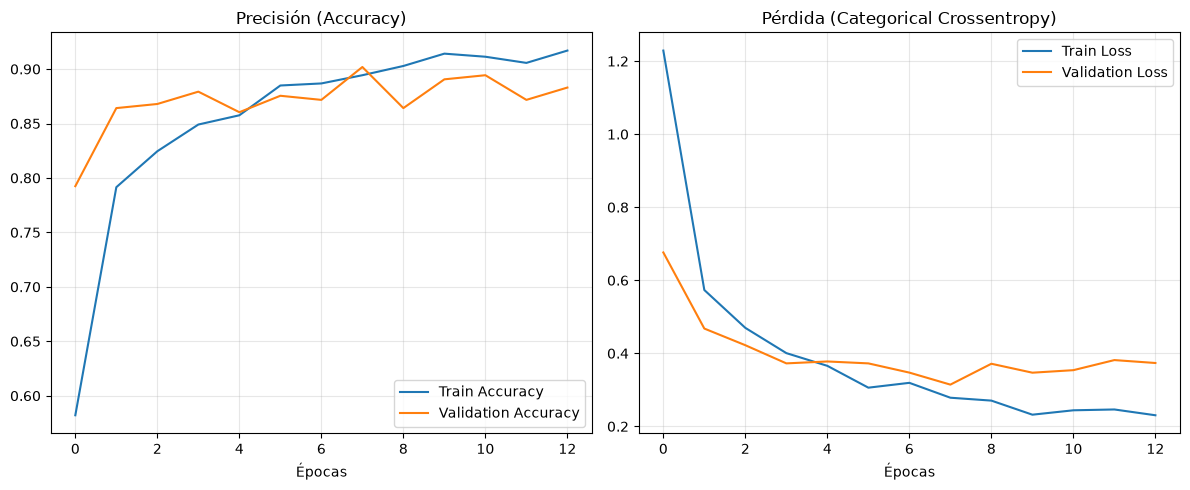


Rendimiento final en el conjunto de Validación:
Pérdida (Loss): 0.3143
Precisión (Accuracy): 90.19%

Modelo final guardado como: modelo_facial.keras


In [6]:
# Evaluación y gráficas de rendimiento
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 5))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Precisión (Accuracy)')
plt.xlabel('Épocas')
plt.grid(True, alpha=0.3)

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Pérdida (Categorical Crossentropy)')
plt.xlabel('Épocas')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Resumen final
val_loss_final, val_acc_final = model.evaluate(val_ds, verbose=0)
print(f"\nRendimiento final en el conjunto de Validación:")
print(f"Pérdida (Loss): {val_loss_final:.4f}")
print(f"Precisión (Accuracy): {val_acc_final*100:.2f}%")
print("\nModelo final guardado como: modelo_facial.keras")